# Figure 1: AMOC strength in the abrupt CO2 runs

AMOC strength is the maximum of the Eulerian-mean streamfunction north of 45N. The curves are smoothed with a
fourth-order Butterworth filter with a 15-year cutoff.

Input: `amoc_ann_CESM104_{abrupt2x_2500,abrupt4x_5900,abrupt8x_5100,control_1000}.nc`

In [1]:
import numpy as np
import xarray as xr
import matplotlib
import matplotlib.pyplot as plt
import common

matplotlib.rc('font', size=16)

In [2]:
strength = {run: common.amoc_strength(f'amoc_ann_CESM104_{name}.nc')
            for run, name in {'2xCO2': 'abrupt2x_2500', '4xCO2': 'abrupt4x_5900', '8xCO2': 'abrupt8x_5100'}.items()}
control_mean = common.amoc_strength('amoc_ann_CESM104_control_1000.nc').mean(dim='time')
print(f'piControl mean: {float(control_mean):.2f} Sv')

piControl mean: 20.29 Sv


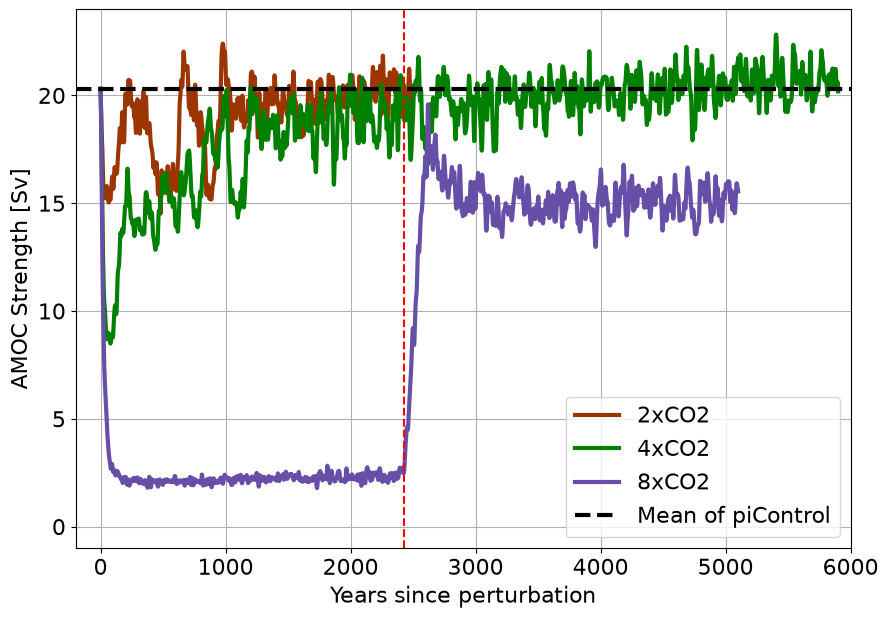

In [3]:
colors = {'2xCO2': '#9c3601', '4xCO2': 'green', '8xCO2': '#674ea7'}

plt.subplots(figsize=(10, 7))
for run, series in strength.items():
    plt.plot(series.time, common.butterworth_lowpass(series.values), label=run, linewidth=3, color=colors[run])
plt.axhline(control_mean, linestyle='--', color='black', label='Mean of piControl', linewidth=3)
plt.axvline(common.RECOVERY_YEAR, color='red', linestyle='--')
plt.legend()
plt.grid()
plt.ylabel('AMOC Strength [Sv]')
plt.xlabel('Years since perturbation')
plt.ylim([-1, 24])
plt.xlim([-200, 6000])
plt.savefig(common.figure_path('fig01_amoc_strength.png'))
plt.show()